Notebook này tái lập đầy đủ toàn bộ quy trình thực nghiệm và số liệu trình bày trong **Chương 4** của báo cáo đồ án **Triển khai mô hình dự đoán tỷ lệ nhấp quảng cáo (CTR)**, gồm 5 thử nghiệm chính và 2 mục phân tích chuyên sâu:

- **Phần 0:** Nạp dữ liệu & Phân tách tập Train/Test 80/20 có phân tầng (Mục 3.4)
- **Thử nghiệm 1:** Huấn luyện và so sánh 3 mô hình phân loại cơ bản (Mục 4.2 – 4.3)
- **Thử nghiệm 2:** Kiểm định chéo phân tầng 5 lần, kiểm định McNemar & đánh giá quá khớp (Mục 4.4.1 – 4.4.2)
- **Thử nghiệm 3:** Kiểm tra độ nhạy dữ liệu & tiền xử lý — bản ghi trùng lặp và rò rỉ thống kê của Scaler (Mục 4.4.3 – 4.4.4)
- **Phân tích bổ sung:** Độ quan trọng của đặc trưng & Chất lượng xác suất / Hiệu chỉnh (Mục 4.5 – 4.6)
- **Thử nghiệm 4:** Chọn ngưỡng quyết định tối ưu theo chi phí nghiệp vụ (Mục 4.7)
- **Thử nghiệm 5:** Tinh chỉnh siêu tham số (`RandomizedSearchCV`) & Mô hình tham chiếu `HistGradientBoosting` (Mục 4.8 – 4.9)

---
## Phần 0: Nạp dữ liệu & Phân tách tập Train/Test (Mục 3.4)

- Đọc tập dữ liệu đã tiền xử lý `data/processed/ctr_cleaned.csv` (10,000 mẫu, 5 đặc trưng + 1 nhãn).
- Đồng thời chuẩn bị bản dữ liệu gốc chưa chuẩn hóa (đọc từ `data/raw/` hoặc khôi phục ngược từ `models/scaler.pkl`) để phục vụ các thí nghiệm kiểm định chéo chuẩn hóa trong từng fold (Mục 4.4.1) và kiểm tra rò rỉ thống kê (Mục 4.4.4).
- Phân tách **80% huấn luyện (8,000 mẫu) / 20% kiểm thử (2,000 mẫu)** với `stratify=y` và `random_state=42`.

In [10]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import joblib
from scipy.stats import chi2

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix,
    log_loss, brier_score_loss
)

try:
    import matplotlib.pyplot as plt
    HAS_PLT = True
except ImportError:
    HAS_PLT = False
    print("Lưu ý: Chưa cài đặt matplotlib (chạy 'pip install matplotlib' để hiển thị biểu đồ).")

# Định nghĩa đường dẫn và cột đặc trưng
DATA_PROCESSED = Path('../../data/processed/ctr_cleaned.csv')
DATA_RAW_DIR = Path('../../data/raw')
SCALER_PATH = Path('../../models/scaler.pkl')

NUMERIC_COLS = [
    'Daily Time Spent on Site',
    'Age',
    'Area Income',
    'Daily Internet Usage'
]
FEATURE_COLS = NUMERIC_COLS + ['Gender']
TARGET_COL = 'Clicked on Ad'

# 1. Đọc dữ liệu đã tiền xử lý (nhất quán với pipeline hiện tại)
df = pd.read_csv(DATA_PROCESSED)
X = df[FEATURE_COLS].copy()
y = df[TARGET_COL].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Chuẩn bị dữ liệu thô chưa chuẩn hóa (phục vụ Thử nghiệm 2 & 3b)
raw_candidates = [
    DATA_RAW_DIR / 'ad_10000records.csv',
    DATA_RAW_DIR / 'click_through_rate.csv',
]
raw_file = next((p for p in raw_candidates if p.exists()), None)
if raw_file is None and DATA_RAW_DIR.exists():
    csv_files = list(DATA_RAW_DIR.glob('*.csv'))
    raw_file = csv_files[0] if csv_files else None

if raw_file is not None:
    df_raw_full = pd.read_csv(raw_file)
    df_raw = df_raw_full[FEATURE_COLS + [TARGET_COL]].copy()
    if not pd.api.types.is_numeric_dtype(df_raw['Gender']):
        df_raw['Gender'] = df_raw['Gender'].astype(str).str.strip().map({'Male': 1, 'Female': 0}).astype(int)
    print(f"Đã nạp dữ liệu gốc từ: {raw_file}")
elif SCALER_PATH.exists():
    scaler_saved = joblib.load(SCALER_PATH)
    df_raw = df[FEATURE_COLS + [TARGET_COL]].copy()
    df_raw[NUMERIC_COLS] = scaler_saved.inverse_transform(df_raw[NUMERIC_COLS])
    print("Không thấy file trong data/raw/, đã khôi phục dữ liệu gốc bằng inverse_transform từ scaler.pkl.")
else:
    df_raw = df[FEATURE_COLS + [TARGET_COL]].copy()
    print("Cảnh báo: Không tìm thấy file gốc và scaler.pkl, tạm dùng dữ liệu đã xử lý.")

X_raw = df_raw[FEATURE_COLS].copy()
y_raw = df_raw[TARGET_COL].copy()

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

print(f"Kích thước tập huấn luyện: {X_train.shape} | Tỷ lệ click: {y_train.mean():.3%}")
print(f"Kích thước tập kiểm thử  : {X_test.shape} | Tỷ lệ click: {y_test.mean():.3%}")

Đã nạp dữ liệu gốc từ: ..\..\data\raw\ad_10000records.csv
Kích thước tập huấn luyện: (8000, 5) | Tỷ lệ click: 49.175%
Kích thước tập kiểm thử  : (2000, 5) | Tỷ lệ click: 49.150%


---
## Thử nghiệm 1: Huấn luyện và So sánh 3 Mô hình Cơ bản (Mục 4.2 – 4.3)

So sánh 3 thuật toán đại diện cho 3 trường phái trên cùng tập huấn luyện (8,000 mẫu) và tập kiểm thử (2,000 mẫu):
1. **Logistic Regression** (`max_iter=1000`) — mô hình tuyến tính làm mốc cơ sở.
2. **Gaussian Naive Bayes** (`GaussianNB()`) — mô hình xác suất.
3. **Random Forest** (`n_estimators=100, random_state=42`) — mô hình tập hợp cây quyết định.

Tính đầy đủ: Accuracy, Khoảng tin cậy 95% (Bootstrap 1,000 lần), Precision, Recall, F1-Score, ROC-AUC và Ma trận nhầm lẫn (TP, TN, FP, FN).

In [11]:
def bootstrap_acc_ci(y_true, y_pred, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    y_true_arr = np.asarray(y_true)
    y_pred_arr = np.asarray(y_pred)
    n = len(y_true_arr)
    accs = []
    for _ in range(n_boot):
        idx = rng.randint(0, n, size=n)
        accs.append(np.mean(y_true_arr[idx] == y_pred_arr[idx]))
    low, high = np.percentile(accs, [2.5, 97.5])
    return low, high

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Gaussian Naive Bayes': GaussianNB(),
    'Random Forest (mặc định)': RandomForestClassifier(n_estimators=100, random_state=42),
}

trained_models = {}
test_preds = {}
test_probs = {}
summary_rows = []
cm_rows = []

# Mốc cơ sở (luôn đoán lớp đa số: 0 - không nhấp)
majority_acc = (y_test == 0).mean()
summary_rows.append({
    'Mô hình': 'Mốc cơ sở (luôn đoán không nhấp)',
    'Accuracy': round(majority_acc, 3),
    'KTC 95% (acc)': '–',
    'Precision': '–',
    'Recall': 0.000,
    'F1': '–',
    'ROC-AUC': 0.500
})

for name, clf in models.items():
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    prob = clf.predict_proba(X_test)[:, 1]
    
    trained_models[name] = clf
    test_preds[name] = pred
    test_probs[name] = prob
    
    ci_low, ci_high = bootstrap_acc_ci(y_test, pred)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    
    summary_rows.append({
        'Mô hình': name,
        'Accuracy': round(accuracy_score(y_test, pred), 3),
        'KTC 95% (acc)': f"{ci_low:.3f} – {ci_high:.3f}",
        'Precision': round(precision_score(y_test, pred), 3),
        'Recall': round(recall_score(y_test, pred), 3),
        'F1': round(f1_score(y_test, pred), 3),
        'ROC-AUC': round(roc_auc_score(y_test, prob), 3),
    })
    cm_rows.append({
        'Mô hình': name, 'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    })

print("=== Bảng 4.3: Hiệu năng các mô hình trên tập kiểm thử (2,000 mẫu) ===")
display(pd.DataFrame(summary_rows))

print("\n=== Bảng 4.4: Số lượng TP, TN, FP, FN của từng mô hình ===")
display(pd.DataFrame(cm_rows))

=== Bảng 4.3: Hiệu năng các mô hình trên tập kiểm thử (2,000 mẫu) ===


,Mô hình,Accuracy,KTC 95% (acc),Precision,Recall,F1,ROC-AUC
0,Mốc cơ sở (luôn đoán không nhấp),0.508,–,–,0.000,–,0.500
1,Logistic Regression,0.712,0.693 – 0.732,0.721,0.674,0.697,0.774
2,Gaussian Naive Bayes,0.712,0.693 – 0.733,0.744,0.631,0.683,0.776
3,Random Forest (mặc định),0.783,0.765 – 0.801,0.789,0.763,0.776,0.856



=== Bảng 4.4: Số lượng TP, TN, FP, FN của từng mô hình ===


,Mô hình,TP,TN,FP,FN
0,Logistic Regression,663,761,256,320
1,Gaussian Naive Bayes,620,804,213,363
2,Random Forest (mặc định),750,816,201,233


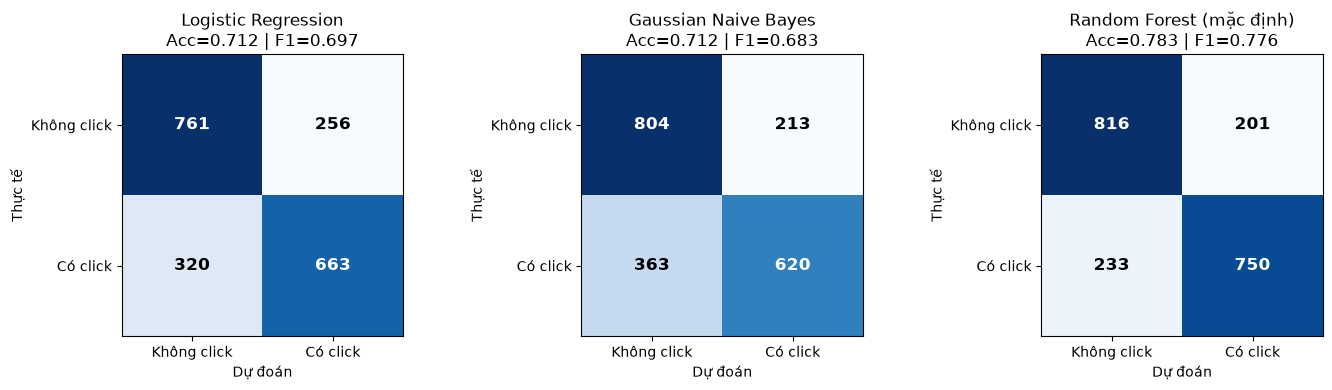

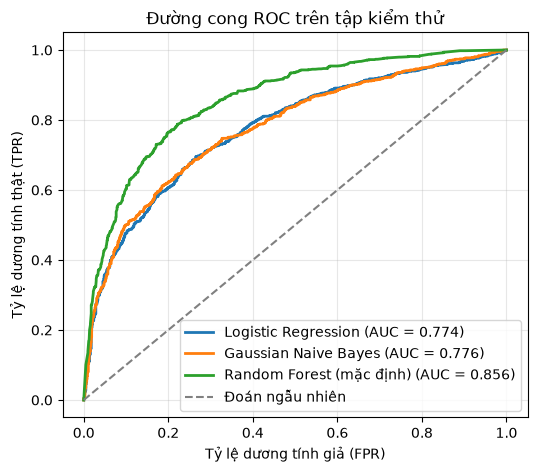

In [12]:
# Vẽ Ma trận nhầm lẫn & Đường cong ROC (Hình 4.1 & 4.2)
if HAS_PLT:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (name, pred) in zip(axes, test_preds.items()):
        cm = confusion_matrix(y_test, pred)
        ax.imshow(cm, cmap='Blues')
        ax.set_title(f"{name}\nAcc={accuracy_score(y_test, pred):.3f} | F1={f1_score(y_test, pred):.3f}")
        ax.set_xticks([0, 1]); ax.set_xticklabels(['Không click', 'Có click'])
        ax.set_yticks([0, 1]); ax.set_yticklabels(['Không click', 'Có click'])
        ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế')
        for i in range(2):
            for j in range(2):
                color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
                ax.text(j, i, str(cm[i, j]), ha='center', va='center', color=color, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 5))
    for name, prob in test_probs.items():
        fpr, tpr, _ = roc_curve(y_test, prob)
        auc_val = roc_auc_score(y_test, prob)
        plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.3f})")
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Đoán ngẫu nhiên')
    plt.xlabel('Tỷ lệ dương tính giả (FPR)')
    plt.ylabel('Tỷ lệ dương tính thật (TPR)')
    plt.title('Đường cong ROC trên tập kiểm thử')
    plt.legend(loc='lower right')
    plt.grid(alpha=0.3)
    plt.show()

---
## Thử nghiệm 2: Kiểm định Độ tin cậy — Kiểm định chéo 5 lần, Kiểm định McNemar & Quá khớp (Mục 4.4.1 – 4.4.2)

- **Mục 4.4.1a (Kiểm định chéo phân tầng 5 lần):** Toàn bộ pipeline (`StandardScaler` chỉ fit trên phần train của từng fold + mô hình) được huấn luyện và đánh giá trên 5 fold cho cả 3 mô hình và mô hình tham chiếu `HistGradientBoostingClassifier`.
- **Mục 4.4.1b (Kiểm định McNemar):** Kiểm tra sự khác biệt có ý nghĩa thống kê giữa từng cặp mô hình trên cùng 2,000 mẫu kiểm thử.
- **Mục 4.4.2 (Hiện tượng quá khớp):** Đối chiếu Accuracy trên tập huấn luyện vs tập kiểm thử và thống kê độ sâu / số lá của Random Forest mặc định.

In [13]:
# 2a. Kiểm định chéo phân tầng 5 lần (Bảng 4.5)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_pipeline(estimator):
    preprocessor = ColumnTransformer(
        transformers=[('scaler', StandardScaler(), NUMERIC_COLS)],
        remainder='passthrough'
    )
    return Pipeline([('prep', preprocessor), ('clf', estimator)])

cv_models = {
    'Logistic Regression': make_pipeline(LogisticRegression(max_iter=1000)),
    'Gaussian Naive Bayes': make_pipeline(GaussianNB()),
    'Random Forest (mặc định)': make_pipeline(RandomForestClassifier(n_estimators=100, random_state=42)),
    'HistGradientBoosting (tham chiếu)': make_pipeline(HistGradientBoostingClassifier(random_state=42)),
}

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_rows = []
for name, pipe in cv_models.items():
    scores = cross_validate(pipe, X_raw, y_raw, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        'Mô hình': name,
        'Accuracy': f"{scores['test_accuracy'].mean():.3f} ± {scores['test_accuracy'].std():.3f}",
        'Precision': f"{scores['test_precision'].mean():.3f} ± {scores['test_precision'].std():.3f}",
        'Recall': f"{scores['test_recall'].mean():.3f} ± {scores['test_recall'].std():.3f}",
        'F1': f"{scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}",
        'ROC-AUC': f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}",
    })

print("=== Bảng 4.5: Kiểm định chéo phân tầng 5 lần (trung bình ± độ lệch chuẩn) ===")
display(pd.DataFrame(cv_rows))

# 2b. Kiểm định McNemar với hiệu chỉnh liên tục (Bảng 4.6)
def mcnemar_test(y_true, pred_a, pred_b):
    correct_a = (pred_a == y_true)
    correct_b = (pred_b == y_true)
    only_a = int(np.sum(correct_a & ~correct_b))
    only_b = int(np.sum(~correct_a & correct_b))
    denom = only_a + only_b
    chi2_stat = ((abs(only_a - only_b) - 1) ** 2) / denom if denom > 0 else 0.0
    p_val = chi2.sf(chi2_stat, df=1)
    return only_a, only_b, chi2_stat, p_val

pairs = [
    ('Random Forest (mặc định)', 'Logistic Regression'),
    ('Random Forest (mặc định)', 'Gaussian Naive Bayes'),
    ('Logistic Regression', 'Gaussian Naive Bayes'),
]

mc_rows = []
for name_a, name_b in pairs:
    only_a, only_b, stat, p_val = mcnemar_test(y_test.values, test_preds[name_a], test_preds[name_b])
    mc_rows.append({
        'Cặp so sánh (A so với B)': f"{name_a} vs {name_b}",
        'Chỉ A đúng': only_a,
        'Chỉ B đúng': only_b,
        'χ² (hiệu chỉnh)': round(stat, 2),
        'p-value': f"{p_val:.2e}" if p_val < 0.001 else f"{p_val:.4f}"
    })

print("\n=== Bảng 4.6: Kiểm định McNemar giữa các cặp mô hình trên tập kiểm thử ===")
display(pd.DataFrame(mc_rows))

# 2c. Kiểm tra hiện tượng quá khớp (Bảng 4.7)
overfit_rows = []
for name, clf in trained_models.items():
    acc_tr = accuracy_score(y_train, clf.predict(X_train))
    acc_te = accuracy_score(y_test, test_preds[name])
    overfit_rows.append({
        'Mô hình': name,
        'Accuracy train': round(acc_tr, 3),
        'Accuracy test': round(acc_te, 3),
        'Chênh lệch (điểm %)': round((acc_tr - acc_te) * 100, 1)
    })

print("\n=== Bảng 4.7: Accuracy trên tập huấn luyện và tập kiểm thử ===")
display(pd.DataFrame(overfit_rows))

rf_default = trained_models['Random Forest (mặc định)']
avg_depth = np.mean([tree.get_depth() for tree in rf_default.estimators_])
avg_leaves = np.mean([tree.get_n_leaves() for tree in rf_default.estimators_])
print(f"Cấu trúc Random Forest mặc định: độ sâu trung bình = {avg_depth:.1f} tầng, số lá trung bình = {avg_leaves:.0f} lá/cây.")

=== Bảng 4.5: Kiểm định chéo phân tầng 5 lần (trung bình ± độ lệch chuẩn) ===


,Mô hình,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.721 ± 0.005,0.728 ± 0.006,0.690 ± 0.006,0.709 ± 0.006,0.775 ± 0.005
1,Gaussian Naive Bayes,0.723 ± 0.005,0.756 ± 0.008,0.645 ± 0.005,0.696 ± 0.005,0.776 ± 0.006
2,Random Forest (mặc định),0.779 ± 0.011,0.783 ± 0.012,0.763 ± 0.014,0.773 ± 0.012,0.855 ± 0.008
3,HistGradientBoosting (tham chiếu),0.798 ± 0.009,0.811 ± 0.011,0.769 ± 0.014,0.789 ± 0.010,0.877 ± 0.008



=== Bảng 4.6: Kiểm định McNemar giữa các cặp mô hình trên tập kiểm thử ===


,Cặp so sánh (A so với B),Chỉ A đúng,Chỉ B đúng,χ² (hiệu chỉnh),p-value
0,Random Forest (mặc định) vs Logistic Regression,310,168,41.59,1.12e-10
1,Random Forest (mặc định) vs Gaussian Naive Bayes,302,160,43.03,5.38e-11
2,Logistic Regression vs Gaussian Naive Bayes,48,48,0.01,0.9187



=== Bảng 4.7: Accuracy trên tập huấn luyện và tập kiểm thử ===


,Mô hình,Accuracy train,Accuracy test,Chênh lệch (điểm %)
0,Logistic Regression,0.725,0.712,1.3
1,Gaussian Naive Bayes,0.726,0.712,1.4
2,Random Forest (mặc định),0.965,0.783,18.2


Cấu trúc Random Forest mặc định: độ sâu trung bình = 27.3 tầng, số lá trung bình = 1585 lá/cây.


---
## Thử nghiệm 3: Kiểm tra Độ nhạy Dữ liệu & Tiền xử lý (Mục 4.4.3 – 4.4.4)

### 3a. Ảnh hưởng của bản ghi trùng lặp (Mục 4.4.3)
- Tách 2,000 mẫu kiểm thử thành 2 nhóm: **có bản sao** (trùng cả 5 đặc trưng với ít nhất 1 mẫu trong tập train) và **không có bản sao**.
- Đo tỷ lệ trùng nhãn giữa bản sao trong tập train và nhãn thực tế ở tập test (nhiễu nhãn).
- Chạy lại kiểm định chéo 5 lần trên tập dữ liệu đã loại bỏ bản ghi trùng (5 đặc trưng + nhãn).

### 3b. Vai trò của chuẩn hóa & rò rỉ thống kê của Scaler (Mục 4.4.4)
- So sánh Accuracy trên tập kiểm thử giữa 3 cách làm: (1) Scaler fit trên toàn bộ dữ liệu (như notebook tiền xử lý), (2) Scaler fit chỉ trên tập train, và (3) Không chuẩn hóa.

In [14]:
# 3a. Phân tích mẫu có bản sao trong tập kiểm thử (Bảng 4.8)
train_keys = set(map(tuple, np.round(X_train[FEATURE_COLS].values, 6)))
test_tuples = list(map(tuple, np.round(X_test[FEATURE_COLS].values, 6)))
has_dup_mask = np.array([t in train_keys for t in test_tuples])

print(f"Tổng mẫu kiểm thử: {len(y_test)} | Không có bản sao: {(~has_dup_mask).sum()} | Có bản sao: {has_dup_mask.sum()} ({has_dup_mask.mean():.1%})")

dup_rows = []
for name, pred in test_preds.items():
    dup_rows.append({
        'Mô hình': name,
        f'Toàn bộ ({len(y_test)})': round(accuracy_score(y_test, pred), 3),
        f'Không có bản sao ({(~has_dup_mask).sum()})': round(accuracy_score(y_test[~has_dup_mask], pred[~has_dup_mask]), 3),
        f'Có bản sao ({has_dup_mask.sum()})': round(accuracy_score(y_test[has_dup_mask], pred[has_dup_mask]), 3),
    })

print("\n=== Bảng 4.8: Accuracy trên tập kiểm thử theo việc có bản sao trong tập huấn luyện ===")
display(pd.DataFrame(dup_rows))

# Kiểm tra độ nhất quán nhãn của các bản sao (nhiễu nhãn)
train_label_map = {}
for t, lbl in zip(map(tuple, np.round(X_train[FEATURE_COLS].values, 6)), y_train.values):
    train_label_map.setdefault(t, []).append(lbl)

dup_matches = []
for t, lbl in zip(test_tuples, y_test.values):
    if t in train_label_map:
        maj_lbl = int(np.round(np.mean(train_label_map[t])))
        dup_matches.append(int(maj_lbl == lbl))
print(f"Tỷ lệ nhãn của bản sao trong tập train trùng với nhãn thực tế ở tập test: {np.mean(dup_matches):.1%}")

# Kiểm định chéo 5 lần sau khi loại bỏ trùng lặp (5 đặc trưng + nhãn)
df_dedup = df_raw.drop_duplicates(subset=FEATURE_COLS + [TARGET_COL]).reset_index(drop=True)
X_dedup = df_dedup[FEATURE_COLS]
y_dedup = df_dedup[TARGET_COL]

print(f"\nKiểm định chéo 5 lần sau khi xóa bản ghi trùng (còn {len(df_dedup)} dòng):")
dedup_rows = []
for name, pipe in cv_models.items():
    sc = cross_validate(pipe, X_dedup, y_dedup, cv=cv, scoring='accuracy', n_jobs=-1)
    dedup_rows.append({
        'Mô hình': name,
        'Accuracy CV (đã xóa trùng)': f"{sc['test_score'].mean():.3f} ± {sc['test_score'].std():.3f}"
    })
display(pd.DataFrame(dedup_rows))

Tổng mẫu kiểm thử: 2000 | Không có bản sao: 1429 | Có bản sao: 571 (28.5%)

=== Bảng 4.8: Accuracy trên tập kiểm thử theo việc có bản sao trong tập huấn luyện ===


,Mô hình,Toàn bộ (2000),Không có bản sao (1429),Có bản sao (571)
0,Logistic Regression,0.712,0.687,0.774
1,Gaussian Naive Bayes,0.712,0.689,0.769
2,Random Forest (mặc định),0.783,0.769,0.818


Tỷ lệ nhãn của bản sao trong tập train trùng với nhãn thực tế ở tập test: 80.9%

Kiểm định chéo 5 lần sau khi xóa bản ghi trùng (còn 7997 dòng):


,Mô hình,Accuracy CV (đã xóa trùng)
0,Logistic Regression,0.692 ± 0.009
1,Gaussian Naive Bayes,0.696 ± 0.007
2,Random Forest (mặc định),0.728 ± 0.006
3,HistGradientBoosting (tham chiếu),0.768 ± 0.008


In [15]:
# 3b. So sánh 3 kịch bản chuẩn hóa để kiểm chứng rò rỉ thống kê (Bảng 4.9)
scaler_train_only = StandardScaler()
X_tr_scaled = X_train_raw.copy()
X_te_scaled = X_test_raw.copy()
X_tr_scaled[NUMERIC_COLS] = scaler_train_only.fit_transform(X_train_raw[NUMERIC_COLS])
X_te_scaled[NUMERIC_COLS] = scaler_train_only.transform(X_test_raw[NUMERIC_COLS])

scale_rows = []
model_factories = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=1000),
    'Gaussian Naive Bayes': lambda: GaussianNB(),
    'Random Forest (mặc định)': lambda: RandomForestClassifier(n_estimators=100, random_state=42),
}

for name, factory in model_factories.items():
    # (1) Fit toàn bộ dữ liệu (từ ctr_cleaned.csv)
    acc_full = accuracy_score(y_test, test_preds[name])
    
    # (2) Fit chỉ trên tập train
    m2 = factory()
    m2.fit(X_tr_scaled, y_train_raw)
    acc_train_only = accuracy_score(y_test_raw, m2.predict(X_te_scaled))
    
    # (3) Không chuẩn hóa
    m3 = factory()
    m3.fit(X_train_raw, y_train_raw)
    acc_raw = accuracy_score(y_test_raw, m3.predict(X_test_raw))
    
    scale_rows.append({
        'Mô hình': name,
        'Scaler fit toàn bộ dữ liệu': f"{acc_full:.4f}",
        'Scaler fit chỉ trên tập train': f"{acc_train_only:.4f}",
        'Không chuẩn hóa': f"{acc_raw:.4f}",
    })

print("=== Bảng 4.9: Accuracy trên tập kiểm thử theo cách chuẩn hóa ===")
display(pd.DataFrame(scale_rows))

=== Bảng 4.9: Accuracy trên tập kiểm thử theo cách chuẩn hóa ===


,Mô hình,Scaler fit toàn bộ dữ liệu,Scaler fit chỉ trên tập train,Không chuẩn hóa
0,Logistic Regression,0.7120,0.7120,0.7120
1,Gaussian Naive Bayes,0.7120,0.7120,0.7115
2,Random Forest (mặc định),0.7830,0.7830,0.7835


---
## Phân tích bổ sung: Độ quan trọng Đặc trưng & Chất lượng Xác suất (Mục 4.5 – 4.6)

*(Lưu ý: Đây là bước phân tích hậu kiểm trực tiếp trên các mô hình đã huấn luyện ở Thử nghiệm 1.)*
- **Mục 4.5:** Đối chiếu độ quan trọng **Gini** (tính trên tập train) và **Độ quan trọng hoán vị — Permutation Importance** (lặp 20 lần trên tập test).
- **Mục 4.6:** Đánh giá chất lượng xác suất đầu ra bằng **Log-loss**, **Brier score**, **ROC-AUC** và biểu đồ độ tin cậy (Calibration).

In [16]:
# Mục 4.5: Độ quan trọng đặc trưng của Random Forest (Bảng 4.10)
rf_default = trained_models['Random Forest (mặc định)']
perm = permutation_importance(
    rf_default, X_test, y_test,
    n_repeats=20, random_state=42, scoring='accuracy', n_jobs=-1
)

fi_df = pd.DataFrame({
    'Đặc trưng': FEATURE_COLS,
    'Độ quan trọng Gini': np.round(rf_default.feature_importances_, 3),
    'Hoán vị TB (điểm % acc)': np.round(perm.importances_mean * 100, 1),
    'Độ lệch chuẩn (điểm %)': np.round(perm.importances_std * 100, 1),
}).sort_values('Hoán vị TB (điểm % acc)', ascending=False)

fi_df['Độ quan trọng hoán vị (điểm %)'] = (
    fi_df['Hoán vị TB (điểm % acc)'].astype(str) + ' ± ' + fi_df['Độ lệch chuẩn (điểm %)'].astype(str)
)

print("=== Bảng 4.10: Độ quan trọng của các đặc trưng trong Random Forest ===")
display(fi_df[['Đặc trưng', 'Độ quan trọng Gini', 'Độ quan trọng hoán vị (điểm %)']])

# Mục 4.6: Chất lượng xác suất (Bảng 4.11)
prob_rows = []
for name, prob in test_probs.items():
    prob_rows.append({
        'Mô hình': name,
        'Log-loss': round(log_loss(y_test, prob), 3),
        'Brier': round(brier_score_loss(y_test, prob), 3),
        'ROC-AUC': round(roc_auc_score(y_test, prob), 3),
    })

print("\n=== Bảng 4.11: Các độ đo dựa trên xác suất trên tập kiểm thử ===")
display(pd.DataFrame(prob_rows))

=== Bảng 4.10: Độ quan trọng của các đặc trưng trong Random Forest ===


,Đặc trưng,Độ quan trọng Gini,Độ quan trọng hoán vị (điểm %)
1,Age,0.328,21.0 ± 1.0
3,Daily Internet Usage,0.218,5.9 ± 0.6
2,Area Income,0.203,3.0 ± 0.5
0,Daily Time Spent on Site,0.225,2.0 ± 0.5
4,Gender,0.026,0.4 ± 0.3



=== Bảng 4.11: Các độ đo dựa trên xác suất trên tập kiểm thử ===


,Mô hình,Log-loss,Brier,ROC-AUC
0,Logistic Regression,0.570,0.193,0.774
1,Gaussian Naive Bayes,0.569,0.191,0.776
2,Random Forest (mặc định),0.597,0.155,0.856


---
## Thử nghiệm 4: Chọn Ngưỡng Quyết định theo Chi phí Nghiệp vụ (Mục 4.7)

Thay vì cố định ngưỡng cắt xác suất mặc định $\tau = 0.5$, quét ngưỡng $\tau \in [0.05, 0.95]$ trên xác suất của Random Forest mặc định để tìm ngưỡng tối thiểu hóa tổng chi phí lỗi:

$$\text{Tổng chi phí} = c_{\text{FP}} \cdot \text{FP} + c_{\text{FN}} \cdot \text{FN}$$

với 4 kịch bản tỷ lệ chi phí `FP : FN` là **1:1**, **2:1**, **1:2** và **1:3**.

F1 cực đại = 0.782 tại ngưỡng τ = 0.32 (so với 0.776 tại τ = 0.50)

=== Bảng 4.12: Ngưỡng tối ưu theo tỷ lệ chi phí giữa FP và FN (Random Forest mặc định) ===


,Tỷ lệ chi phí FP : FN,Ngưỡng tối ưu,FP,FN,Tổng chi phí,Chi phí tại ngưỡng 0.5,Mức giảm (%)
0,1 : 1,0.50,201,233,434,434,0.0%
1,2 : 1,0.66,114,360,588,635,7.4%
2,1 : 2,0.32,355,124,603,667,9.6%
3,1 : 3,0.21,501,64,693,900,23.0%


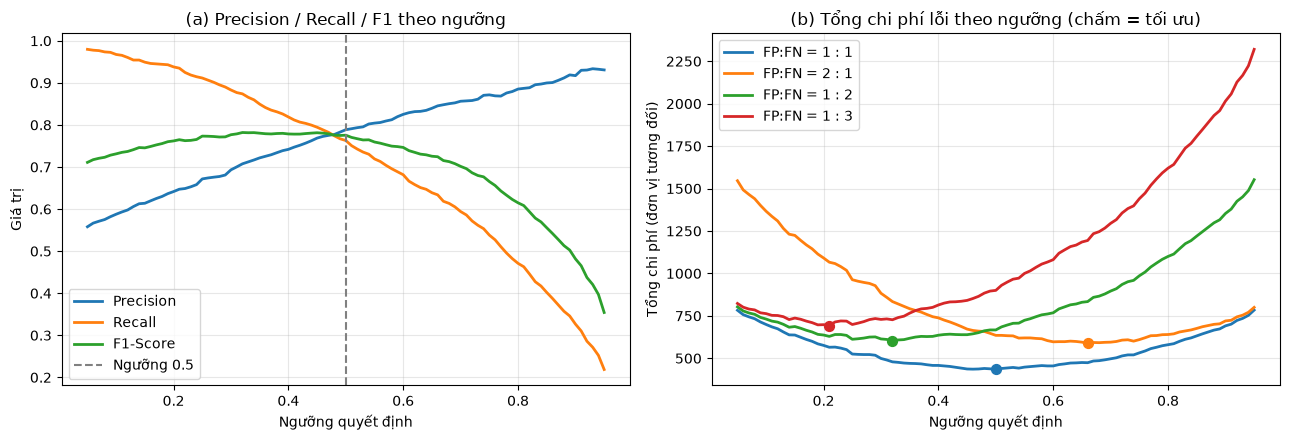

In [17]:
rf_prob = test_probs['Random Forest (mặc định)']
thresholds = np.round(np.arange(0.05, 0.955, 0.01), 2)

# Tính Precision, Recall, F1 theo ngưỡng
precisions, recalls, f1s = [], [], []
for t in thresholds:
    p_t = (rf_prob > t).astype(int)
    precisions.append(precision_score(y_test, p_t, zero_division=0))
    recalls.append(recall_score(y_test, p_t, zero_division=0))
    f1s.append(f1_score(y_test, p_t, zero_division=0))

best_f1_idx = int(np.argmax(f1s))
print(f"F1 cực đại = {f1s[best_f1_idx]:.3f} tại ngưỡng τ = {thresholds[best_f1_idx]:.2f} (so với {f1_score(y_test, (rf_prob > 0.5).astype(int)):.3f} tại τ = 0.50)")

# Tối ưu ngưỡng theo 4 tỷ lệ chi phí FP : FN (Bảng 4.12)
cost_ratios = [(1, 1), (2, 1), (1, 2), (1, 3)]
cost_rows = []
cost_curves = {}

tn_05, fp_05, fn_05, tp_05 = confusion_matrix(y_test, (rf_prob > 0.5).astype(int)).ravel()

for c_fp, c_fn in cost_ratios:
    costs = []
    fps_list, fns_list = [], []
    for t in thresholds:
        p_t = (rf_prob > t).astype(int)
        _, fp_t, fn_t, _ = confusion_matrix(y_test, p_t).ravel()
        costs.append(c_fp * fp_t + c_fn * fn_t)
        fps_list.append(fp_t)
        fns_list.append(fn_t)
    
    cost_curves[f"{c_fp} : {c_fn}"] = costs
    best_idx = int(np.argmin(costs))
    cost_at_05 = c_fp * fp_05 + c_fn * fn_05
    best_cost = costs[best_idx]
    reduction = (cost_at_05 - best_cost) / cost_at_05 * 100
    
    cost_rows.append({
        'Tỷ lệ chi phí FP : FN': f"{c_fp} : {c_fn}",
        'Ngưỡng tối ưu': f"{thresholds[best_idx]:.2f}",
        'FP': fps_list[best_idx],
        'FN': fns_list[best_idx],
        'Tổng chi phí': best_cost,
        'Chi phí tại ngưỡng 0.5': cost_at_05,
        'Mức giảm (%)': f"{reduction:.1f}%"
    })

print("\n=== Bảng 4.12: Ngưỡng tối ưu theo tỷ lệ chi phí giữa FP và FN (Random Forest mặc định) ===")
display(pd.DataFrame(cost_rows))

if HAS_PLT:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(thresholds, precisions, label='Precision', lw=2)
    axes[0].plot(thresholds, recalls, label='Recall', lw=2)
    axes[0].plot(thresholds, f1s, label='F1-Score', lw=2)
    axes[0].axvline(0.5, ls='--', color='gray', label='Ngưỡng 0.5')
    axes[0].set_title('(a) Precision / Recall / F1 theo ngưỡng')
    axes[0].set_xlabel('Ngưỡng quyết định'); axes[0].set_ylabel('Giá trị')
    axes[0].legend(); axes[0].grid(alpha=0.3)
    
    for label, costs in cost_curves.items():
        b_idx = int(np.argmin(costs))
        axes[1].plot(thresholds, costs, lw=2, label=f"FP:FN = {label}")
        axes[1].scatter(thresholds[b_idx], costs[b_idx], s=50, zorder=5)
    axes[1].set_title('(b) Tổng chi phí lỗi theo ngưỡng (chấm = tối ưu)')
    axes[1].set_xlabel('Ngưỡng quyết định'); axes[1].set_ylabel('Tổng chi phí (đơn vị tương đối)')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

---
## Thử nghiệm 5: Tinh chỉnh Siêu tham số & Mô hình Tham chiếu (Mục 4.8 – 4.9)

- Chạy `RandomizedSearchCV` (**30 tổ hợp**, **5-fold CV** trên tập huấn luyện, chỉ số tối ưu `roc_auc`) cho Random Forest với không gian siêu tham số:
  - `n_estimators` $\in \{100, 200, 300, 500\}$
  - `max_depth` $\in \{\text{None}, 6, 8, 10, 12, 16\}$
  - `min_samples_leaf` $\in \{1, 3, 5, 10, 15, 20\}$
  - `max_features` $\in \{\text{'sqrt'}, 0.6, 1.0\}$
- Đánh giá cấu hình tinh chỉnh tốt nhất trên tập kiểm thử và đối chiếu với **Random Forest mặc định** cùng mô hình tham chiếu **HistGradientBoostingClassifier**.
- Vẽ biểu đồ hiệu chỉnh xác suất (Hình 4.6) và xuất bảng tổng hợp lựa chọn mô hình cuối cùng (Mục 4.9).

Cấu hình tốt nhất từ RandomizedSearchCV: {'n_estimators': 300, 'min_samples_leaf': 3, 'max_features': 0.6, 'max_depth': 12}
ROC-AUC kiểm định chéo 5 lần tốt nhất: 0.864

=== Bảng 4.13: So sánh Random Forest mặc định, Random Forest tinh chỉnh và mô hình tham chiếu ===


,Mô hình,Acc,Precision,Recall,F1,ROC-AUC,Log-loss,Brier,Acc train,Chênh lệch train-test (điểm %)
0,RF mặc định (đã triển khai),0.783,0.789,0.763,0.776,0.856,0.597,0.155,0.965,18.2
1,RF tinh chỉnh,0.801,0.822,0.760,0.790,0.877,0.445,0.143,0.871,7.0
2,HistGradientBoosting (tham chiếu),0.809,0.818,0.786,0.802,0.886,0.426,0.137,0.852,4.3


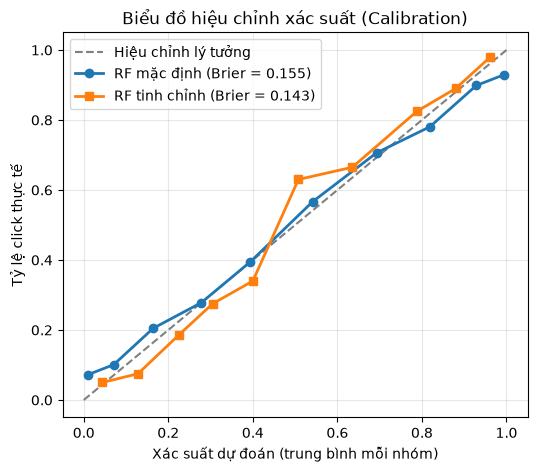

In [18]:
# 5a. Tinh chỉnh siêu tham số bằng RandomizedSearchCV (Mục 4.8)
param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 6, 8, 10, 12, 16],
    'min_samples_leaf': [1, 3, 5, 10, 15, 20],
    'max_features': ['sqrt', 0.6, 1.0],
}

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)
search.fit(X_train, y_train)

print("Cấu hình tốt nhất từ RandomizedSearchCV:", search.best_params_)
print(f"ROC-AUC kiểm định chéo 5 lần tốt nhất: {search.best_score_:.3f}")

# Huấn luyện mô hình tinh chỉnh & mô hình tham chiếu HistGradientBoosting
rf_tuned = search.best_estimator_
hgb = HistGradientBoostingClassifier(random_state=42)
hgb.fit(X_train, y_train)

compare_models = {
    'RF mặc định (đã triển khai)': trained_models['Random Forest (mặc định)'],
    'RF tinh chỉnh': rf_tuned,
    'HistGradientBoosting (tham chiếu)': hgb,
}

comp_rows = []
for name, clf in compare_models.items():
    pred_te = clf.predict(X_test)
    prob_te = clf.predict_proba(X_test)[:, 1]
    acc_tr = accuracy_score(y_train, clf.predict(X_train))
    comp_rows.append({
        'Mô hình': name,
        'Acc': round(accuracy_score(y_test, pred_te), 3),
        'Precision': round(precision_score(y_test, pred_te), 3),
        'Recall': round(recall_score(y_test, pred_te), 3),
        'F1': round(f1_score(y_test, pred_te), 3),
        'ROC-AUC': round(roc_auc_score(y_test, prob_te), 3),
        'Log-loss': round(log_loss(y_test, prob_te), 3),
        'Brier': round(brier_score_loss(y_test, prob_te), 3),
        'Acc train': round(acc_tr, 3),
        'Chênh lệch train-test (điểm %)': round((acc_tr - accuracy_score(y_test, pred_te)) * 100, 1),
    })

print("\n=== Bảng 4.13: So sánh Random Forest mặc định, Random Forest tinh chỉnh và mô hình tham chiếu ===")
display(pd.DataFrame(comp_rows))

# Vẽ biểu đồ hiệu chỉnh xác suất (Hình 4.6: RF mặc định vs RF tinh chỉnh)
if HAS_PLT:
    plt.figure(figsize=(6, 5))
    plt.plot([0, 1], [0, 1], '--', color='gray', label='Hiệu chỉnh lý tưởng')
    
    for label, clf, marker in [
        ('RF mặc định', trained_models['Random Forest (mặc định)'], 'o'),
        ('RF tinh chỉnh', rf_tuned, 's')
    ]:
        prob = clf.predict_proba(X_test)[:, 1]
        brier = brier_score_loss(y_test, prob)
        frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=10, strategy='quantile')
        plt.plot(mean_pred, frac_pos, marker=marker, lw=2, label=f"{label} (Brier = {brier:.3f})")
    
    plt.xlabel('Xác suất dự đoán (trung bình mỗi nhóm)')
    plt.ylabel('Tỷ lệ click thực tế')
    plt.title('Biểu đồ hiệu chỉnh xác suất (Calibration)')
    plt.legend(loc='upper left')
    plt.grid(alpha=0.3)
    plt.show()

---
## Tổng kết Mục 4.9: Lựa chọn Mô hình Cuối cùng

- **Random Forest** được chọn làm mô hình triển khai vì đạt hiệu năng cao nhất và ổn định nhất trên tập kiểm thử lẫn kiểm định chéo 5 lần, vượt trội có ý nghĩa thống kê so với Logistic Regression và Gaussian Naive Bayes (McNemar $p < 10^{-9}$).
- Cấu hình tinh chỉnh ở Thử nghiệm 5 cho thấy khả năng giảm mạnh hiện tượng quá khớp và cải thiện Log-loss, được khuyến nghị làm bản nâng cấp cho phiên bản tiếp theo.
